### (Opcional) El gradiente de política, visto en 2D

El aprendizaje por refuerzo del notebook principal se basa en una idea: **hacer más probables las acciones que llevaron a buenos resultados**. Aquí la vemos funcionar en un problema pequeño que se puede dibujar, adaptado del ejemplo *Windy Highway* de Duane Rich.

Tres ideas:

1. Una **política** es una regla que da la probabilidad de cada acción en cada estado.
2. **REINFORCE**: se sube la probabilidad de las acciones en proporción a la recompensa que siguió.
3. Restar una **línea base** (lo que se esperaba obtener) hace el aprendizaje mucho más eficiente.


#### El entorno y el agente, en código

Todo el problema cabe en una clase: el entorno (viento y recompensa), la política y la regla de aprendizaje. Puedes leerla ahora o volver a ella después de ver los gráficos.


In [1]:
import numpy as np


def hexagonal_grid(n: int, size: float = 0.95) -> np.ndarray:
    """n x n points on a hexagonal grid covering [0, size]^2: the centers of the policy's features."""
    xv, yv = np.meshgrid(np.arange(n), np.arange(n), indexing="xy")
    ratio = np.sqrt(3) / 2
    xv = xv * ratio
    xv[::2, :] += ratio / 2
    xv = xv * (size / xv.max())
    yv = yv * (size / yv.max())
    return np.stack([xv.ravel(), yv.ravel()], axis=1)


class WindyHighway:
    """The environment, a linear-softmax policy, and REINFORCE (optionally with a learned baseline)."""

    ACTIONS = ("left", "right", "up")

    def __init__(self, alpha, distance_scaler, protos_per_dim, seed=0, with_baseline=False, reward_shift=0.0,
                 alpha_value=0.1, distance_scaler_value=0.15, protos_per_dim_value=3, max_wind_strength=0.02):
        self.alpha, self.sigma = alpha, distance_scaler
        self.with_baseline, self.reward_shift = with_baseline, reward_shift
        self.alpha_value, self.sigma_value = alpha_value, distance_scaler_value
        self.max_wind = max_wind_strength
        self.rng = np.random.default_rng(seed)
        self.G0s = []  # total return of each episode

        self.protos = hexagonal_grid(protos_per_dim) + 0.025
        self.theta = np.zeros((len(self.protos), 2))  # weights for 'left' and 'right'; 'up' has score 0
        if with_baseline:
            self.protos_value = hexagonal_grid(protos_per_dim_value) + 0.025
            self.w = np.zeros(len(self.protos_value))  # baseline weights

    # --- features: smooth bumps centered on the grid points ---
    def features(self, s, baseline=False):
        protos, sigma = (self.protos_value, self.sigma_value) if baseline else (self.protos, self.sigma)
        bumps = np.exp(-(((s - protos) / sigma) ** 2).sum(axis=1))
        return bumps / bumps.sum()

    # --- environment ---
    def reward_at(self, s):
        return float(np.sin(s[0] * 2 * np.pi) + self.reward_shift)

    def step(self, s, action):
        x, y = s
        y = y + self.rng.uniform(0.04, 0.06)  # always moves up
        if action == "left":
            x = x - self.rng.uniform(0.04, 0.06)
        elif action == "right":
            x = x + self.rng.uniform(0.04, 0.06)
        x = x - np.cos(s[0] * 2 * np.pi) * self.max_wind  # wind
        s_next = np.array([x, y]).clip(0.0, 1.0)
        return s_next, self.reward_at(s_next)

    # --- policy: softmax over three scores ---
    def action_probs(self, s):
        scores = np.append((self.theta * self.features(s)[:, None]).sum(axis=0), 0.0)
        z = np.exp(scores)
        return z / z.sum()

    def grad_log_prob(self, s, action):
        """Gradient of log π(action | s) with respect to theta."""
        phi, pi = self.features(s), self.action_probs(s)
        grad = -np.outer(phi, pi[:2])
        a = self.ACTIONS.index(action)
        if a < 2:
            grad[:, a] += phi
        return grad

    # --- one episode and the REINFORCE update ---
    def play_episode(self):
        s = np.array([self.rng.uniform() * 0.2 + 0.4, 0.0])  # start near x = 0.5
        states, actions, rewards = [s], [], [np.nan]
        while s[1] < 1.0:
            a = self.rng.choice(self.ACTIONS, p=self.action_probs(s))
            s, r = self.step(s, a)
            states.append(s)
            actions.append(a)
            rewards.append(r)
        returns = [float(sum(rewards[t + 1 :])) for t in range(len(rewards) - 1)] + [np.nan]
        return np.array(states), actions, rewards, returns

    def update(self, states, actions, returns):
        for s, a, G in zip(states[:-1], actions, returns[:-1]):
            grad = self.grad_log_prob(s, a)
            if self.with_baseline:
                phi_v = self.features(s, baseline=True)
                advantage = G - float(self.w @ phi_v)
                self.w += self.alpha_value * advantage * phi_v
                self.theta += self.alpha * advantage * grad
            else:
                self.theta += self.alpha * G * grad

    def run(self, num_episodes):
        for _ in range(num_episodes):
            states, actions, _, returns = self.play_episode()
            self.G0s.append(returns[0])
            self.update(states, actions, returns)

    # --- helpers for the plots ---
    def policy_field(self, n_grid=12):
        Xs, Ys = np.meshgrid(np.linspace(0.05, 0.95, n_grid), np.linspace(0.05, 0.95, n_grid))
        probs = np.array([[self.action_probs(np.array([x, y])) for x, y in zip(xr, yr)] for xr, yr in zip(Xs, Ys)])
        return {"X": Xs, "Y": Ys, "left": probs[..., 0], "right": probs[..., 1], "up": probs[..., 2]}

    def reward_landscape(self, n_grid=200):
        Xs, Ys = np.meshgrid(np.linspace(0, 1, n_grid), np.linspace(0, 1, n_grid))
        return {"X": Xs, "Y": Ys, "R": np.sin(Xs * 2 * np.pi) + self.reward_shift}

    def wind_field(self, n_grid=12):
        Xs, Ys = np.meshgrid(np.linspace(0.05, 0.95, n_grid), np.linspace(0.05, 0.95, n_grid))
        return {"X": Xs, "Y": Ys, "U": -np.cos(Xs * 2 * np.pi) * self.max_wind, "V": np.zeros_like(Xs)}

    def returns_curve(self, window=50):
        G = np.array(self.G0s)
        rolling = np.concatenate([np.full(window - 1, np.nan), np.convolve(G, np.ones(window) / window, mode="valid")])
        return {"episode": np.arange(len(G)), "G0": G, "rolling": rolling}


#### El problema

Un agente cruza el cuadrado `[0,1] × [0,1]` de abajo hacia arriba:

- En cada paso sube un poco y elige una acción: `left`, `right` o `up`.
- Un **viento** lo empuja de lado según su posición $x$.
- Recibe una **recompensa** $r(x) = \sin(2\pi x)$ en cada paso: alta cerca de $x = 0.25$ (la autopista), baja cerca de $x = 0.75$ (la zanja).
- El episodio termina al llegar arriba.


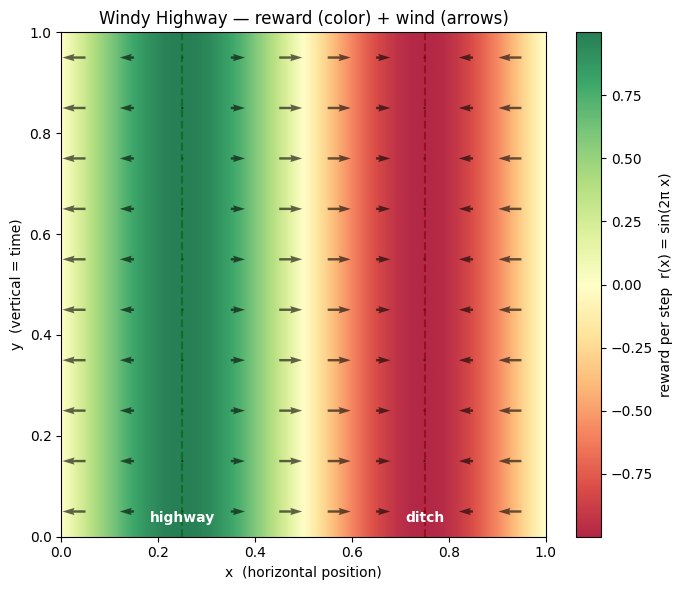

In [2]:
import matplotlib.pyplot as plt

hw = WindyHighway(alpha=0.1, distance_scaler=0.15, protos_per_dim=5, seed=1)

fig, ax = plt.subplots(figsize=(7, 6))
# reward landscape
land = hw.reward_landscape(n_grid=200)
im = ax.imshow(
    land["R"], origin="lower", extent=[0, 1, 0, 1],
    cmap="RdYlGn", aspect="auto", alpha=0.85,
)
fig.colorbar(im, ax=ax, label="reward per step  r(x) = sin(2π x)")

# wind field as a quiver overlay
wf = hw.wind_field(n_grid=10)
ax.quiver(wf["X"], wf["Y"], wf["U"], wf["V"], color="black", scale=0.4, width=0.005, alpha=0.6)

# label the high/low reward bands
ax.axvline(0.25, color="darkgreen", linestyle="--", alpha=0.6)
ax.axvline(0.75, color="darkred",   linestyle="--", alpha=0.6)
ax.text(0.25, 0.03, "highway", ha="center", color="white", weight="bold")
ax.text(0.75, 0.03, "ditch",   ha="center", color="white", weight="bold")

ax.set_xlabel("x  (horizontal position)")
ax.set_ylabel("y  (vertical = time)")
ax.set_title("Windy Highway — reward (color) + wind (arrows)")
plt.tight_layout()
plt.show()

El agente empieza en $x \approx 0.5$, donde el viento lo empuja hacia la derecha, hacia la zanja. Para ganar recompensa tiene que aprender a moverse contra el viento hasta la autopista.


#### La política

En cada punto, la política da una probabilidad a cada acción mediante un softmax sobre tres puntuaciones. Las puntuaciones de `left` y `right` son combinaciones lineales de unas funciones suaves centradas en puntos de una rejilla (la de `up` es 0). Los pesos $\theta$ de esas combinaciones son lo que se entrena.

Usamos este modelo simple en vez de una red neuronal para poder **dibujar** la política. La idea del gradiente es la misma.

Antes de entrenar, $\theta = 0$: las tres acciones tienen probabilidad 1/3 en todas partes.


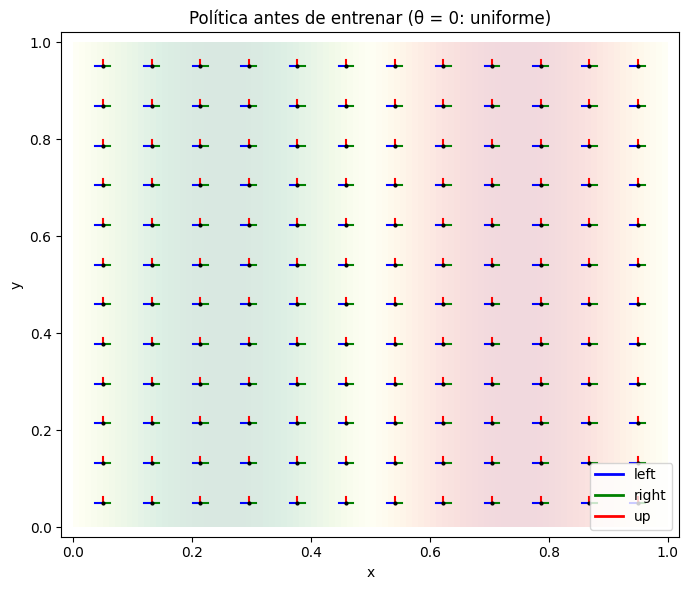

In [3]:
def plot_policy(hw, ax, title=""):
    """Plot the policy as colored arrows over a grid.

    Each grid point draws three arrows whose *lengths* equal the action
    probabilities at that state. Blue = left, green = right, red = up.
    Long arrow ⇒ confident in that action.
    """
    field = hw.policy_field(n_grid=12)
    arrow_len = (1.0 / 12) * 0.45
    for i in range(field["X"].shape[0]):
        for j in range(field["X"].shape[1]):
            x, y = field["X"][i, j], field["Y"][i, j]
            pl, pr, pu = field["left"][i, j], field["right"][i, j], field["up"][i, j]
            ax.plot([x, x - pl * arrow_len], [y, y],            color="blue",  lw=1.5)
            ax.plot([x, x + pr * arrow_len], [y, y],            color="green", lw=1.5)
            ax.plot([x, x],                  [y, y + pu * arrow_len], color="red",   lw=1.5)
            ax.scatter([x], [y], color="black", s=4, zorder=3)
    # Show the reward as a faint backdrop
    land = hw.reward_landscape(n_grid=100)
    ax.imshow(land["R"], origin="lower", extent=[0, 1, 0, 1], cmap="RdYlGn", alpha=0.15, aspect="auto")
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(7, 6))
plot_policy(hw, ax, title="Política antes de entrenar (θ = 0: uniforme)")
# legend
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],color=c,lw=2,label=l) for c,l in
                   [("blue","left"),("green","right"),("red","up")]], loc="lower right")
plt.tight_layout()
plt.show()

#### Un episodio antes de entrenar

Con la política uniforme, el agente se mueve al azar y el viento lo arrastra. Cada punto muestra el **retorno** $G_t$: la suma de las recompensas desde ese paso hasta el final.


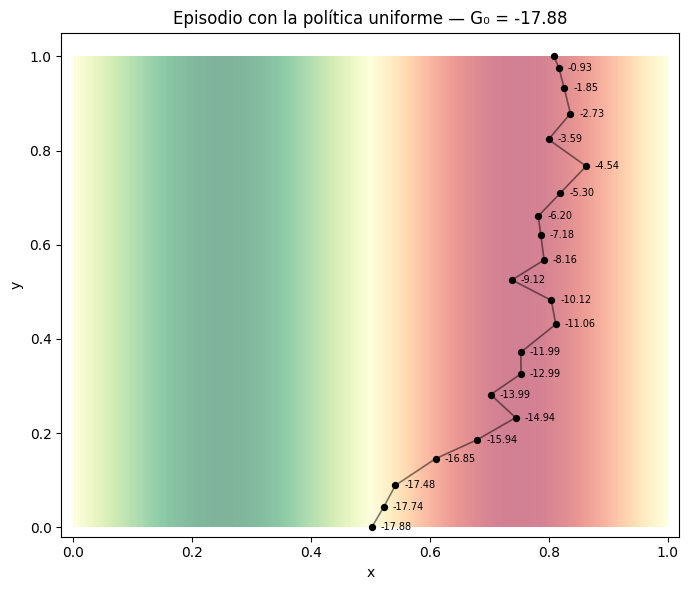

Total return of the episode: G_0 = -17.88


In [4]:
states, actions, rewards, returns = hw.play_episode()
G0 = returns[0]

fig, ax = plt.subplots(figsize=(7, 6))
land = hw.reward_landscape(n_grid=200)
ax.imshow(land["R"], origin="lower", extent=[0, 1, 0, 1], cmap="RdYlGn", alpha=0.5, aspect="auto")
ax.plot(states[:, 0], states[:, 1], color="black", lw=1.2, alpha=0.5)
ax.scatter(states[:, 0], states[:, 1], c="black", s=18, zorder=3)
for t, (x, y) in enumerate(states):
    if not np.isnan(returns[t]):
        ax.text(x + 0.015, y, f"{returns[t]:+.2f}", fontsize=7, va="center")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title(f"Episodio con la política uniforme — G₀ = {G0:+.2f}")
plt.tight_layout()
plt.show()

print(f"Total return of the episode: G_0 = {G0:+.2f}")

#### REINFORCE

Queremos maximizar el retorno esperado. Su gradiente (Williams, 1992) es

$$\nabla_\theta \, \mathbb{E}[G] = \mathbb{E}\Big[\sum_t G_t \, \nabla_\theta \log \pi_\theta(a_t \mid s_t)\Big]$$

y la regla de aprendizaje: $\theta \leftarrow \theta + \alpha \sum_t G_t \, \nabla_\theta \log \pi_\theta(a_t \mid s_t)$.

En palabras: si a una acción le siguió un retorno alto, se vuelve más probable; si le siguió uno bajo, menos. Es la misma regla que usa GRPO en el notebook principal, con tokens en lugar de movimientos.

Entrenamos 3000 episodios.


In [5]:
hw_a = WindyHighway(alpha=0.1, distance_scaler=0.15, protos_per_dim=5, seed=1)
hw_a.run(num_episodes=3000)

#### Curva de aprendizaje

Cada línea gris es el retorno de un episodio; la roja, su media móvil. El retorno sube rápido en los primeros episodios y luego mejora lentamente, con altibajos.


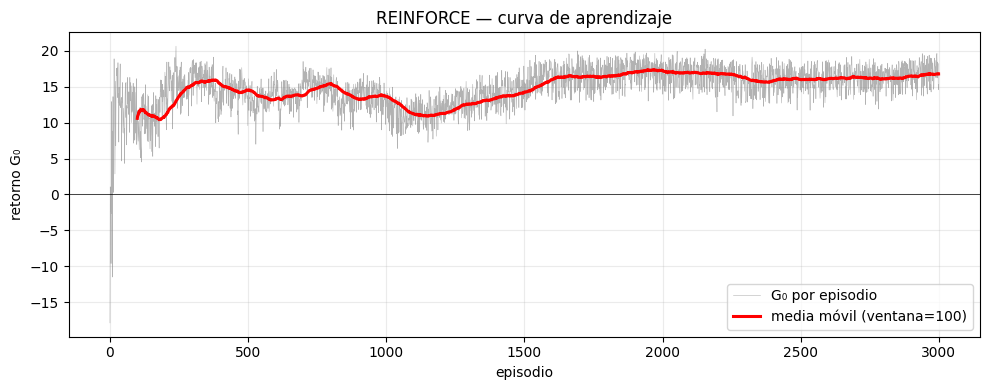

In [6]:
curve = hw_a.returns_curve(window=100)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(curve["episode"], curve["G0"], color="gray", lw=0.4, alpha=0.6, label="G₀ por episodio")
ax.plot(curve["episode"], curve["rolling"], color="red", lw=2.2, label="media móvil (ventana=100)")
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("episodio"); ax.set_ylabel("retorno G₀")
ax.set_title("REINFORCE — curva de aprendizaje")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### La política aprendida

A la izquierda de la autopista domina `right` (verde); a la derecha, `left` (azul). El agente aprendió a converger a $x \approx 0.25$ desde ambos lados. `up` casi desaparece: con viento, siempre conviene corregir.


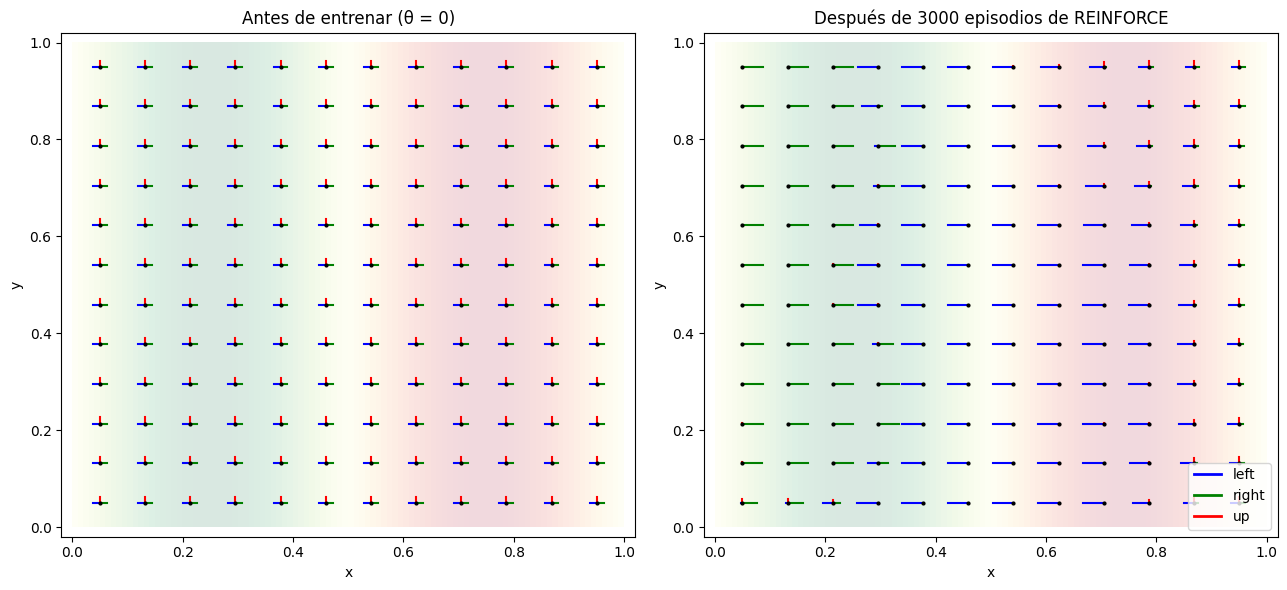

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
hw_init = WindyHighway(alpha=0.1, distance_scaler=0.15, protos_per_dim=5, seed=1)
plot_policy(hw_init, axes[0], title="Antes de entrenar (θ = 0)")
plot_policy(hw_a,    axes[1], title="Después de 3000 episodios de REINFORCE")
axes[1].legend(handles=[Line2D([0],[0],color=c,lw=2,label=l) for c,l in
                        [("blue","left"),("green","right"),("red","up")]], loc="lower right")
plt.tight_layout()
plt.show()

#### Episodios con la política entrenada

Diez episodios: todos terminan cerca de la autopista, a pesar del viento.


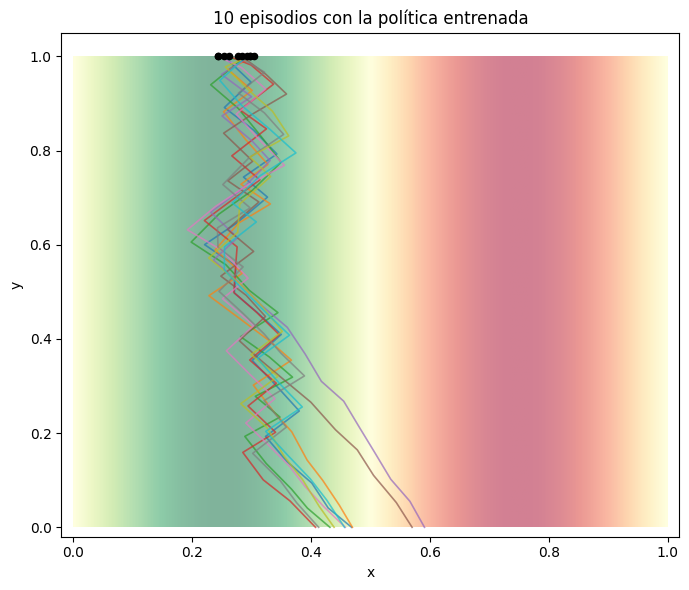

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))
land = hw_a.reward_landscape(n_grid=200)
ax.imshow(land["R"], origin="lower", extent=[0, 1, 0, 1], cmap="RdYlGn", alpha=0.5, aspect="auto")
for k in range(10):
    states, _, _, returns = hw_a.play_episode()
    ax.plot(states[:, 0], states[:, 1], lw=1.2, alpha=0.7)
    ax.scatter(states[-1, 0], states[-1, 1], color="black", s=20, zorder=3)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("10 episodios con la política entrenada")
plt.tight_layout()
plt.show()

#### La línea base

REINFORCE tiene un problema cuando todas las recompensas son positivas: toda acción tomada recibe un empujón hacia arriba, y solo cambia cuánto. Distinguir lo bueno de lo malo es lento.

La solución es restar una **línea base** $b(s)$, lo que se esperaba obtener desde ese estado:

$$\theta \leftarrow \theta + \alpha \sum_t \big(G_t - b(s_t)\big) \, \nabla_\theta \log \pi_\theta(a_t \mid s_t)$$

La diferencia $G_t - b(s_t)$ es la **ventaja**: positiva si salió mejor de lo esperado, negativa si salió peor. Aquí $b(s)$ se aprende junto con la política. GRPO, en el notebook principal, usa en su lugar el promedio de varias respuestas al mismo problema.

Para provocar el problema, sumamos 5 a todas las recompensas y entrenamos agentes idénticos, con y sin línea base. Usamos 6 semillas para cada caso, porque el resultado de una sola ejecución depende mucho del azar.


In [9]:
SHIFT, SEEDS, EPISODES = 5.0, range(6), 2000

curves = {"sin línea base": [], "con línea base": []}
for seed in SEEDS:
    for name, with_baseline in [("sin línea base", False), ("con línea base", True)]:
        agent = WindyHighway(alpha=0.1, distance_scaler=0.15, protos_per_dim=5, seed=seed, reward_shift=SHIFT,
                             with_baseline=with_baseline, distance_scaler_value=0.2, protos_per_dim_value=3)
        agent.run(EPISODES)
        curves[name].append(agent.returns_curve(window=100)["rolling"])


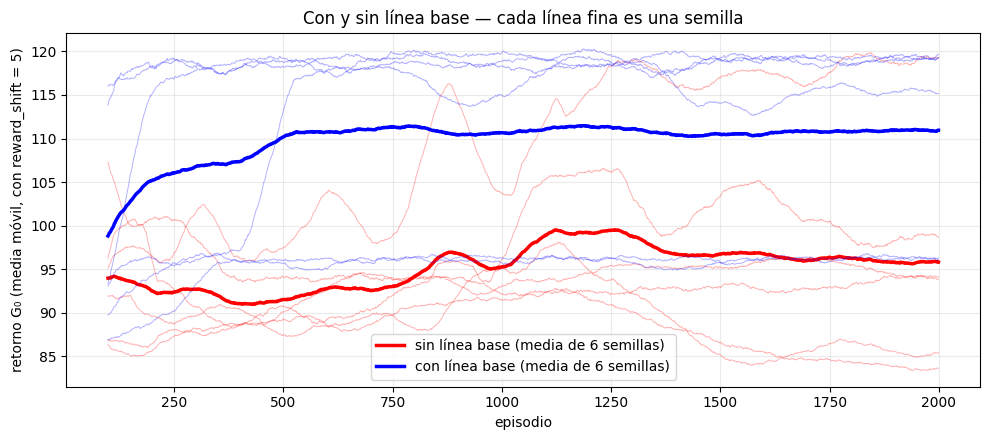

sin línea base: mean return in the first 500 episodes 92.3; runs that reach the highway 1/6
con línea base: mean return in the first 500 episodes 106.1; runs that reach the highway 4/6


In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for (name, runs), color in zip(curves.items(), ["red", "blue"]):
    for run in runs:
        ax.plot(run, color=color, lw=0.7, alpha=0.3)
    ax.plot(np.mean(runs, axis=0), color=color, lw=2.5, label=f"{name} (media de {len(runs)} semillas)")
ax.set_xlabel("episodio"); ax.set_ylabel("retorno G₀ (media móvil, con reward_shift = 5)")
ax.set_title("Con y sin línea base — cada línea fina es una semilla")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for name, runs in curves.items():
    early = np.mean([np.nanmean(run[:500]) for run in runs])
    found = sum(np.nanmean(run[-500:]) > 110 for run in runs)  # ~118 = staying on the highway
    print(f"{name}: mean return in the first 500 episodes {early:.1f}; runs that reach the highway {found}/{len(runs)}")


Con línea base el agente aprende más rápido en todas las semillas y llega a la autopista mucho más a menudo; sin ella, la mayoría de las ejecuciones se quedan atascadas en un retorno menor.

Esto importa en el notebook principal: allí la recompensa vale 0 o 1, nunca es negativa. Sin línea base, una respuesta incorrecta no recibiría ningún empujón hacia abajo.


#### Del agente al modelo de lenguaje

| Este notebook | Notebook principal |
|---|---|
| Estado: posición $(x, y)$ | El texto escrito hasta ahora |
| Acción: `left`, `right`, `up` | El siguiente token |
| Recompensa: $\sin(2\pi x)$ en cada paso | 1 si la respuesta final es correcta, 0 si no |
| Episodio | Una respuesta completa |
| Línea base aprendida $b(s)$ | Promedio de recompensa de varias respuestas al mismo problema |

La regla es la misma: **hacer más probable lo que salió mejor de lo esperado.** La política aprende exactamente lo que la recompensa premia; si la recompensa premia algo distinto de lo que queremos, la política lo explota.
